<a href="https://colab.research.google.com/github/kalpakjian/ivdc_handout/blob/main/colab/yolo_only.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 只要 YOLO（最小版）

四個執行格，不需要 clone、不需要其他腳本。簡報第 7 頁那個「四行方案」就是這個。

**關於 webcam**：Colab 沒有相機，所以線上只能用「圖片」或「影片」；
**自己的電腦**有 webcam，直接 `--source 0`（見最後一格說明）。

## 1. 安裝（Colab 沒預裝 ultralytics）

In [1]:
%pip install -q ultralytics
import ultralytics
print("ultralytics", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.202


## 2. 單張圖片

6 個物件，最高信心 0.87，推論 12.0 ms
  bus          0.873
  person       0.866
  person       0.853
  person       0.825
  person       0.261
  stop sign    0.255


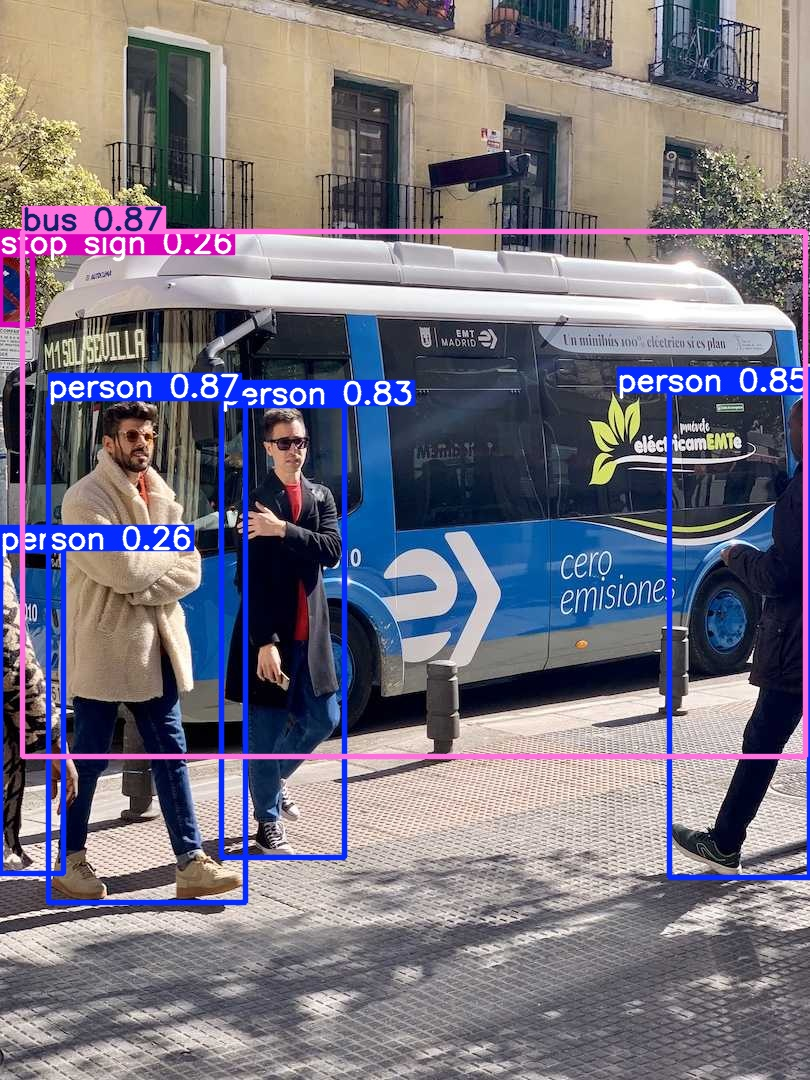

In [2]:
import urllib.request, os
from ultralytics import YOLO
from IPython.display import Image, display

if not os.path.exists("bus.jpg"):
    urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", "bus.jpg")

model = YOLO("yolov8n.pt")          # 第一次會下載 ~6 MB
r = model.predict(source="bus.jpg", imgsz=640, conf=0.25, verbose=False)[0]

print(f"{len(r.boxes)} 個物件，最高信心 {float(r.boxes.conf.max()):.2f}，"
      f"推論 {r.speed['inference']:.1f} ms")
for c, cf in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist()):
    print(f"  {r.names[int(c)]:12s} {cf:.3f}")
r.save(filename="yolo_bus.jpg")
display(Image("yolo_bus.jpg", width=640))

## 3. 「即時偵測」：用影片取代攝影機

frame 0: 5 個物件, 推論 12.5 ms
frame 1: 6 個物件, 推論 11.8 ms
frame 2: 6 個物件, 推論 11.8 ms
共 30 幀


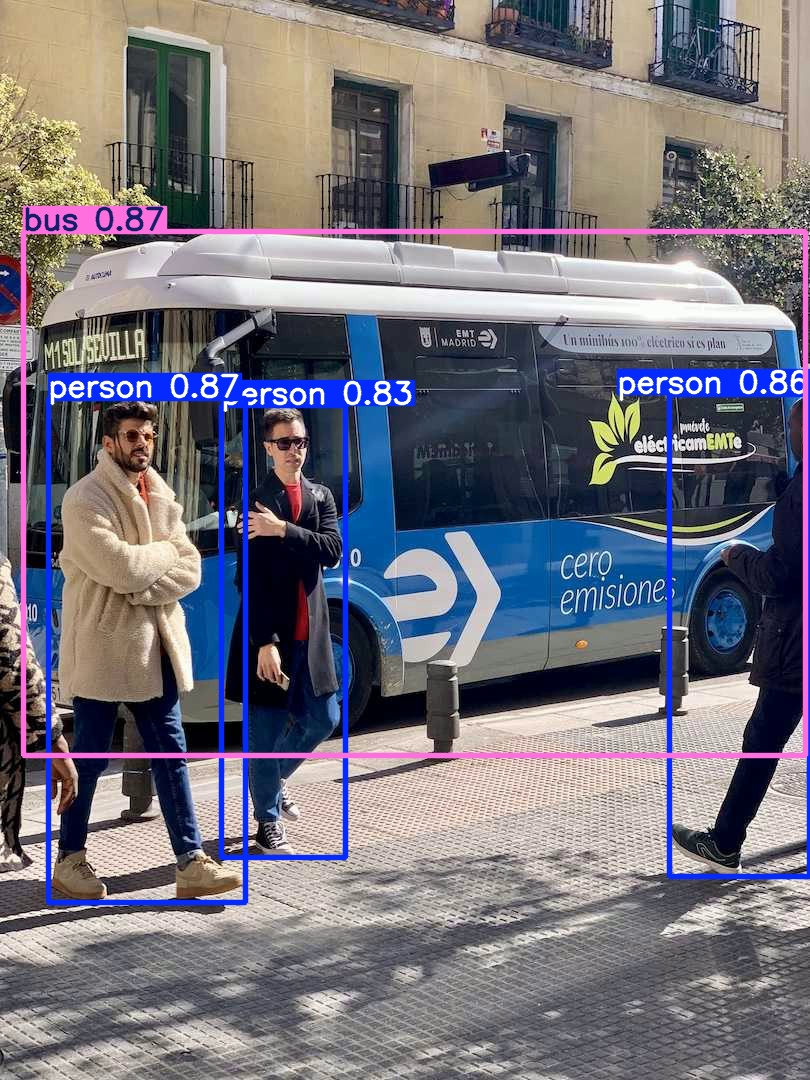

In [3]:
import cv2
img = cv2.imread("bus.jpg")
w = cv2.VideoWriter("clip.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 15.0,
                    (img.shape[1], img.shape[0]))
for _ in range(30):
    w.write(img)
w.release()

for i, r in enumerate(model.predict(source="clip.mp4", imgsz=640, conf=0.25,
                                    stream=True, verbose=False)):
    if i < 3:
        print(f"frame {i}: {len(r.boxes)} 個物件, 推論 {r.speed['inference']:.1f} ms")
    last = r
print("共", i + 1, "幀")
last.save(filename="yolo_clip_last.jpg")
display(Image("yolo_clip_last.jpg", width=640))

## 4. webcam 版（在**自己的電腦**跑才有畫面）

Colab 沒有相機，這一格在 Colab 會失敗。回到本機終端機：

```bash
# 最精簡：四行
python -c "
from ultralytics import YOLO
model = YOLO('yolov8n.pt')
model.predict(source=0, show=True)
"

# 或直接用 repo 的腳本（多了自動挑相機、FPS、存檔、headless 退回）
python src/05_yolo_detection.py --source 0 --show
python src/05_yolo_detection.py --source 0 --show --imgsz 960
python src/05_yolo_detection.py --source clip.mp4 --show      # 沒相機時
```

按 <kbd>q</kbd> 或關掉視窗結束。若出現 `Could not find the Qt platform plugin "wayland"`，
它會自動退回 X11，不影響；真的彈不出窗就加 `--no-show`，圖會存在 `out/yolo/`。